# Figure S7 — robustness of the multitask-RNN results

One of two Extended Data figures on the multitask RNN (183 mm wide). Heavy computation lives in `src/mtrnn/panels/` and is
cached in `results/panels/<name>.pkl`; every plotting cell only reads the cache. The trained networks of the main
RNN figure (Figure 5) are reused; nothing is retrained. The ReLU networks are the 10 of `figure_5.ipynb`, and the
Softplus networks are trained the same way. The one exception is the right plot of panel g: five further sets of 10 ReLU networks,
trained on the same 27 tasks with pursuit's answer partly on the shared eye ring (`configs/pursuit_dial_g*.json`).

| panel | content |
|---|---|
| a | final performance on each task, ReLU and Softplus |
| b | split-half reliability of the cross-task generalization index, with a label-shuffle null |
| c | TI-only minus TD-only across-task decoding at 10 / 20 / 30 % tails |
| d, e | Softplus: % TI and % TD by category; TD-only / random / TI-only decoding |
| f | % TI vs 20-unit across-task decoding within each category (mixed model, random intercept per network) |
| g | the two analog pairs with added activity noise, next to the data's three-point values; right, Sac vs Pursuit as pursuit's answer moves onto the shared eye ring |
| h | % TI and % TD by category over training, with performance at each checkpoint |

**Exclusion:** a network is left out of every pair containing a task it performs below 0.90. This is Yang et al. 2019's criterion,
applied per network-task combination; applied per network it would remove 9 of the 10 ReLU networks, all for DNMS. The main figure
(`figure_5.ipynb`) uses the same rule. Panel a and the stats file list what was dropped.

**Statistics:** the unit of analysis is the network (n = 10). Values are averaged over the pairs of a category within each
network, then compared with paired two-sided Wilcoxon signed-rank tests (exact p; with n = 10 the smallest possible p is
0.002). Slopes are fitted inside each network and the 10 slopes are tested against zero.

**Outputs** (in `analysis/figures/figure_s7/`):
- `figs7.{pdf,svg,png}`
- `panels/<letter>.pdf`
- `figs7_stats.md`

Supplement to the multitask-RNN main figure, Figure 5 (`figure_5.ipynb`); what the TI and TD units do is Figure S8 (`figure_s8.ipynb`, same cache and setup).

In [1]:
# ── setup: style, colours, layout helpers, cache ──
import os, sys, pickle, warnings
sys.path.insert(0, os.getcwd())                 # run from analysis/: paper_style.py, paper_stats.py, figure_layout.py
from paper_style import *                       # TI / TD / Int / random colours, coupling colours, puts ROOT on sys.path
from paper_stats import StatsTable
ST = StatsTable('figure_s7')          # Supplementary Table 1 rows (ED Fig. 7)
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import wilcoxon, spearmanr
from mtrnn import panels as EC, readout as Q
warnings.filterwarnings('ignore', category=RuntimeWarning)

OUT = figure_dir('figure_s7'); PANEL_DIR = OUT + 'panels/'; os.makedirs(PANEL_DIR, exist_ok=True); NAME = 'figs7'
# text sizes: the paper type scale (paper_style: axis labels 6 pt, ticks, legends and annotations 5 pt); 8-pt bold panel letters
apply_style()                                   # the shared type scale (paper_style); this figure also keeps 1-pt data lines
mpl.rcParams.update({'lines.linewidth': 1, 'pdf.fonttype': 42, 'ps.fonttype': 42})
LBL, TCK, LEG = FS_LABEL, FS_TICK, FS_LEGEND

TYPES = EC.TYPES
TYPE_C = {'same operation': '#2F6DB5', 'different operation': '#8DB8E8', 'spatial vs abstract': '#9C6ADE', 'reversed mapping': '#E8412C'}
TYPE_TICK = {'same operation': 'Same\nfam.', 'different operation': 'Diff.\nfam.', 'spatial vs abstract': 'Spat. vs\nabstr.', 'reversed mapping': 'Rev.\nmap.'}
TYPE_FULL = {'same operation': 'Same task family', 'different operation': 'Different task family', 'spatial vs abstract': 'Spatial vs abstract response',
             'reversed mapping': 'Reversed mapping'}   # Supplementary Table 1 dataset names
TYPE_LAB = {'same operation': 'Same fam.', 'different operation': 'Diff. fam.', 'spatial vs abstract': 'Spat. vs abstr.', 'reversed mapping': 'Rev. map.'}
ACT_C = {'ReLU': '#E8412C', 'Softplus': '#1E86B5'}
FAM_ORDER = [('Go', ['Go', 'RT Go', 'Dly Go', 'Go Mod1', 'Go Mod2', 'Sac']), ('Anti', ['Anti', 'RT Anti', 'Dly Anti']),
             ('Decision', ['DM 1', 'DM 2', 'Ctx DM 1', 'Ctx DM 2', 'MultSen DM']),
             ('Delayed decision', ['Dly DM 1', 'Dly DM 2', 'Ctx Dly DM 1', 'Ctx Dly DM 2', 'MultSen Dly DM']),
             ('Matching', ['DMS', 'DNMS', 'DMC', 'DNMC']), ('Pursuit', ['Pursuit']), ('Yes / no', ['Cat', 'Cat-B', 'Match'])]
TASK_ORDER = [t for _, ts in FAM_ORDER for t in ts]
FIVE, FIVE_TICKS = EC.FIVE, ['TI\nsame', 'TI\nopp.', 'TD\nsame', 'TD\nopp.', 'ctrl']
FIVE_STYLE = [(COUP_DARK, .9), (COUP_DARK, .4), (COUP_LIGHT, .9), (COUP_LIGHT, .4), (COUP_CTL, .9)]   # the noise-correlation bar colours (extra_noise_correlations)

C = lambda name: EC.load(name)
STATS = {}                                       # panel -> list of lines for the stats file
def stat(panel, line):
    STATS.setdefault(panel, []).append(line); print(f'  [{panel}] {line}')
pfmt = lambda p: f'{p:.2g}' if p >= 1e-3 else f'{p:.1e}'
def wsr(x, y=None):
    # paired two-sided Wilcoxon signed-rank, exact for n <= 25
    r = wilcoxon(x, y, alternative='two-sided', method='exact') if y is not None else wilcoxon(x, alternative='two-sided', method='exact')
    return float(r.pvalue)

def net_dots(ax, x, v, c, rng, width=.09, ms=3, open_=True):
    # open circles = networks, filled = mean ± s.e.m.
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    if not len(v): return
    ax.scatter(x + rng.uniform(-width, width, len(v)), v, s=ms, facecolor='white' if open_ else c, edgecolor=c, lw=.5, alpha=.9, zorder=2, clip_on=False)
    ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=3, color=c, capsize=0, elinewidth=.8, zorder=3)
def mean_sem(ax, x, v, c, ms=3):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    ax.errorbar(x, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=ms, color=c, capsize=0, elinewidth=.8, zorder=4)
def type_axis(ax):
    ax.set_xticks(range(len(TYPES))); ax.set_xticklabels([TYPE_TICK[t] for t in TYPES], fontsize=FS_TICK)
    for lab, t in zip(ax.get_xticklabels(), TYPES): lab.set_color(TYPE_C[t])
    ax.set_xlim(-.6, len(TYPES) - .4); ax.tick_params(axis='x', length=0, pad=2)
def top_legend(ax, handles, labels, ncol=None, y=1.0):
    ax.legend(handles, labels, fontsize=LEG, loc='lower left', bbox_to_anchor=(0, y), handletextpad=.1, borderaxespad=0,
              ncol=ncol or len(labels), columnspacing=.6, handlelength=1.0)
dot = lambda c, mfc=None: Line2D([], [], marker='o', ls='', color=c, mfc=mfc or c, ms=3)

# ── layout in millimetres: 183 mm wide, 6-mm outer margins, axes placed by absolute position (left, top, width, height) ──
MM = 1 / 25.4
FIG_W, FIG_H = 183, 142
COL = {1: 14, 2: 56, 3: 100, 4: 145}             # left edges of the four columns
ROW = {1: 13, 2: 63, 3: 105}                      # top edges of the three rows
RH = 25                                           # axes height of a row (row 1 is taller)
LAYOUT = {
    'a': [(COL[1], ROW[1], 72, 28)],
    'b': [(COL[3], ROW[1], 30, 28)],
    'c': [(COL[4], ROW[1], 32, 28)],
    'd': [(COL[1], ROW[2], 30, RH)],
    'e': [(COL[2], ROW[2], 30, RH)],
    'f': [(COL[3] + i * 19.5, ROW[2], 16, RH) for i in range(4)],
    'g': [(COL[1] + i * 26, ROW[3], 20, RH) for i in range(3)],
    'h': [(COL[3], ROW[3], 20, RH), (COL[3] + 23, ROW[3], 20, RH), (COL[3] + 56, ROW[3], 21, RH)],
}
def add_axes_mm(fig, left, top, width, height, fw, fh):
    return fig.add_axes([left / fw, 1 - (top + height) / fh, width / fw, height / fh])
print({k: len(v) for k, v in LAYOUT.items()})

{'a': 1, 'b': 1, 'c': 1, 'd': 1, 'e': 1, 'f': 4, 'g': 3, 'h': 3}


In [2]:
# ── compute anything that is not cached yet (python -m mtrnn.panels: CPU panels ~20 min, GPU simulations ~3 min, silencing ~40 min on the GPU) ──
need = [p for p in ['performance', 'index_reliability', 'tail_size', 'softplus', 'pct_ti_within_type', 'noise_sweep', 'unit_removal', 'stim_vs_response', 'rule_weights', 'recurrent_weights', 'task_decoding_epochs', 'task_decoding', 'training_trajectory', 'silencing'] if not os.path.exists(f'{EC.CACHE}/{p}.pkl')]
run = {'task_decoding_epochs': EC.simulate_task_decoding, 'training_trajectory': lambda: (EC.simulate_training_trajectory(), EC.panel_training_trajectory())}
for p in need:
    print('computing', p); (run.get(p) or EC.PANELS[p])()
print('cache complete' if not need else f'computed {need}')
# panel g is calibrated against the data three-point of the paper's mouse window: same network sweep, new data values (no network is run)
PAPER_WINDOW = EC.PAPER_WINDOW
G_CACHE = f'noise_sweep_{PAPER_WINDOW}'
if not os.path.exists(f'{EC.CACHE}/{G_CACHE}.pkl'): EC.panel_noise_sweep_retarget(PAPER_WINDOW)
# panel g, right: the pursuit-output dial, read from the stored measured read-out of the pursuit_dial_g* networks
DIAL_CACHE = 'pursuit_dial'
if not os.path.exists(f'{EC.CACHE}/{DIAL_CACHE}.pkl'): EC.panel_pursuit_dial(PAPER_WINDOW)

cache complete


## a · final performance on each task

Yang's performance rule on 200 test trials per task; one dot per network. Filled = ReLU (main results), open = Softplus. Tasks are
in the order of the main figure's task matrix. Dashed line = the training criterion (0.95); dotted line = the exclusion threshold
(0.90). A network below 0.90 on a task is left out of every pair containing that task, in every panel. The dropped combinations are
drawn in grey and listed in the stats file.

In [3]:
def draw_a(axs):
    ax = axs[0]; d = C('performance'); P = d['perf']; rng = np.random.default_rng(1); x = {t: i for i, t in enumerate(TASK_ORDER)}
    for act, off, filled in (('ReLU', -.18, True), ('Softplus', .18, False)):
        g = P[P.act == act]; c = np.where(g.perf < d['min_task_perf'], '#AAAAAA', ACT_C[act])
        ax.scatter(g.task.map(x) + off + rng.uniform(-.07, .07, len(g)), g.perf.clip(.3, 1), s=3, lw=.5, edgecolor=c,
                   facecolor=c if filled else 'white', zorder=2, clip_on=False)
    ax.axhline(d['criterion'], color='k', ls='--', lw=.6); ax.axhline(d['min_task_perf'], color='#777777', ls=':', lw=.6)
    k = -.5
    for _, ts in FAM_ORDER[:-1]:
        k += len(ts); ax.axvline(k, color='#DDDDDD', lw=.5, zorder=0)
    ax.set_xticks(range(len(TASK_ORDER))); ax.set_xticklabels(TASK_ORDER, rotation=90, fontsize=FS_TICK); ax.tick_params(axis='x', pad=1)
    ax.set_xlim(-.7, len(TASK_ORDER) - .3); ax.set_ylim(.3, 1.02); ax.set_yticks([.4, .6, .8, 1.0]); ax.set_ylabel('Performance', fontsize=LBL)
    top_legend(ax, [dot(ACT_C['ReLU']), dot(ACT_C['Softplus'], 'white')], ['ReLU', 'Softplus'])

d = C('performance'); P = d['perf']
for act in ('ReLU', 'Softplus'):
    g = P[P.act == act]; per_net = g.groupby('seed').perf.mean()
    stat('a', f'{act}: n = {g.seed.nunique()} networks x {g.task.nunique()} tasks; mean performance {g.perf.mean():.3f} (network means {per_net.min():.3f}–{per_net.max():.3f}); '
              f'task means ≥ 0.9 in {np.mean(g.groupby("task").perf.mean() >= .9) * 100:.0f} % of tasks')
stat('a', f'training criterion {d["criterion"]} (dashed); exclusion threshold {d["min_task_perf"]} (dotted): a network below it on a task leaves every pair with that task, in every panel')
for act, v in d['dropped'].items():
    stat('a', f'{act}: {len(v["combos"])} network-task combinations dropped (' + ', '.join(f'{r["task"]} net {r["seed"]} ({r["perf"]:.2f})' for r in v['combos'])
              + f'); (pair, network) rows kept {v["kept_090"]:,} of {v["pair_rows"]:,} at 0.90 (the earlier 0.80 rule kept {v["kept_080"]:,})')
stat('a', 'applied per network (Yang et al. 2019 drop any network below 0.90 on any task) the rule would remove 9 of 10 ReLU networks and 5 of 10 Softplus networks, almost all for DNMS; DNMS pairs keep 1 ReLU network')

# Supplementary Table 1: one row per task and network type (the dots; networks)
for act in ('ReLU', 'Softplus'):
    g = P[P.act == act]
    for t in TASK_ORDER:
        ST.group('a', g.loc[g.task == t, 'perf'], dataset=f'{act} networks', measure='Task performance', group=t, unit='networks')

  [a] ReLU: n = 10 networks x 27 tasks; mean performance 0.981 (network means 0.962–0.991); task means ≥ 0.9 in 93 % of tasks
  [a] Softplus: n = 10 networks x 27 tasks; mean performance 0.990 (network means 0.976–0.993); task means ≥ 0.9 in 96 % of tasks
  [a] training criterion 0.95 (dashed); exclusion threshold 0.9 (dotted): a network below it on a task leaves every pair with that task, in every panel
  [a] ReLU: 12 network-task combinations dropped (DNMS net 0 (0.81), DNMS net 1 (0.84), DNMS net 2 (0.70), Match net 2 (0.41), DNMS net 3 (0.81), DNMS net 4 (0.88), DNMS net 5 (0.90), Match net 5 (0.31), DNMS net 6 (0.89), DMC net 6 (0.86), DNMS net 8 (0.85), DNMS net 9 (0.87)); (pair, network) rows kept 3,201 of 3,510 at 0.90 (the earlier 0.80 rule kept 3,433)
  [a] Softplus: 6 network-task combinations dropped (DNMS net 3 (0.88), Ctx Dly DM 1 net 5 (0.86), DNMS net 5 (0.86), DNMS net 7 (0.86), DNMS net 8 (0.88), DNMS net 9 (0.85)); (pair, network) rows kept 3,355 of 3,510 at 0.90 (th

## b · split-half reliability of the cross-task generalization index

The test trials of every pair and network are split into two interleaved halves, balanced for task and choice (the paper's
`make_halves`, seed 0). The index of every choice unit is computed separately in each half. Each point is one unit-pair (a random
40,000 of them), coloured by the unit's task-1 within-task choice accuracy on all trials. Spearman r is over all unit-pairs.

**Inset (noise null):** choice labels shuffled within each task, then the split-half r recomputed; 100 repeats, observed r marked.

The stats file gives:
- the fraction of unit-pairs on the anti-diagonal arm and how often their task-1 preference flips between halves;
- how stable TI / TD labels are across halves;
- what changes if a unit is classified only when its preference sign in each task agrees between the halves.

In [4]:
def b_table():
    d = C('index_reliability'); M = d['meta'].copy(); M['hA'], M['hB'] = d['hA'], d['hB']; M = M[np.isfinite(M.hA) & np.isfinite(M.hB)]
    M['flip1'] = M.s1A != M.s1B; M['consistent'] = (M.s1A == M.s1B) & (M.s2A == M.s2B)
    # anti-diagonal arm: closer to the line hB = 1 - hA than to the diagonal, and at least 0.2 apart between halves
    M['anti'] = (np.abs(M.hA + M.hB - 1) < np.abs(M.hA - M.hB)) & (np.abs(M.hA - M.hB) >= .2)
    return M

def draw_b(axs):
    ax = axs[0]; d = C('index_reliability'); M = b_table(); rng = np.random.default_rng(2); S = M.iloc[rng.choice(len(M), min(40000, len(M)), replace=False)]
    sc = ax.scatter(S.hA, S.hB, c=S.within_1, cmap='viridis', vmin=.5, vmax=1, s=.4, lw=0, alpha=.6, rasterized=True)
    ax.plot([0, 1], [0, 1], color='k', ls='--', lw=.5)
    r = spearmanr(M.hA, M.hB)[0]
    ax.text(.04, .96, f'r = {r:.2f}', transform=ax.transAxes, fontsize=LEG, va='top')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1])
    ax.set_xlabel('index, half A', fontsize=LBL); ax.set_ylabel('index, half B', fontsize=LBL)
    cax = ax.inset_axes([.06, .4, .045, .22]); cb = ax.figure.colorbar(sc, cax=cax, ticks=[.5, 1]); cb.ax.tick_params(labelsize=FS_TICK, length=TICK_LEN, pad=1)
    cb.outline.set_linewidth(SPINE_W); cax.set_title('task-1\nwithin acc.', fontsize=FS_ANNOT, pad=1.5)
    ins = ax.inset_axes([.58, .1, .38, .26]); nr = d['null_r']; ins.set_facecolor('white'); ins.set_zorder(5)
    ins.hist(nr, bins=np.linspace(-.1, 1, 45), color='#999999', edgecolor='none'); ins.axvline(r, color='k', lw=.8)
    ins.set_xlim(-.1, 1); ins.set_yticks([]); ins.set_xticks([0, .5, 1]); ins.tick_params(labelsize=FS_TICK, length=TICK_LEN, pad=1)
    ins.spines['left'].set_visible(False); ins.set_title('split-half r', fontsize=FS_ANNOT, pad=1)
    ins.text(.02, .55, 'null', transform=ins.get_xaxis_transform(), fontsize=FS_ANNOT, color='#777777'); ins.text(r - .02, .55, 'data', transform=ins.get_xaxis_transform(), fontsize=FS_ANNOT, ha='right')

d = C('index_reliability'); M = b_table(); r = spearmanr(M.hA, M.hB)[0]; nr = d['null_r']
stat('b', f'n = {len(M):,} unit-pairs ({M.seed.nunique()} networks, {M.groupby(["task_a", "task_b"]).ngroups} pairs; whole-session choice units); split-half Spearman r = {r:.3f}')
stat('b', f'label-shuffle null (100 repeats): r = {nr.mean():.3f} ± {nr.std():.3f} (max {nr.max():.3f}); observed exceeds all 100 → p < 0.01')
ta, tb, la, lb = M.hA.quantile(.8), M.hB.quantile(.8), M.hA.quantile(.2), M.hB.quantile(.2)
cA = np.where(M.hA >= ta, 'TI', np.where(M.hA <= la, 'TD', 'Int')); cB = np.where(M.hB >= tb, 'TI', np.where(M.hB <= lb, 'TD', 'Int'))
stat('b', f'half-A TI still TI in half B: {100 * np.mean(cB[cA == "TI"] == "TI"):.1f} %, TD in half B: {100 * np.mean(cB[cA == "TI"] == "TD"):.2f} %; '
          f'half-A TD still TD: {100 * np.mean(cB[cA == "TD"] == "TD"):.1f} %, TI in half B: {100 * np.mean(cB[cA == "TD"] == "TI"):.2f} % (chance 20 % / 20 %)')
an = M[M.anti]
stat('b', f'anti-diagonal arm (closer to hB = 1 − hA than to the diagonal, |hA − hB| ≥ 0.2): {100 * M.anti.mean():.1f} % of unit-pairs; their task-1 preference flips between halves in '
          f'{100 * an.flip1.mean():.0f} % (rest of the units {100 * M[~M.anti].flip1.mean():.0f} %); median task-1 within accuracy {an.within_1.median():.3f} vs {M[~M.anti].within_1.median():.3f}; '
          f'whole-session class of the arm units: ' + ', '.join(f'{c} {100 * np.mean(an.cls_ti == c):.0f} %' for c in ('TI', 'Int', 'TD')))
stat('b', f'arm units labelled TI in one half and TD in the other: {100 * np.mean(((cA == "TI") & (cB == "TD")) | ((cA == "TD") & (cB == "TI"))):.2f} % of all unit-pairs')
g = M[M.consistent]; rg = spearmanr(g.hA, g.hB)[0]
stat('b', f'consistency gate (preference sign in each task agrees between halves): keeps {100 * M.consistent.mean():.1f} % of unit-pairs '
          f'(TI {100 * M[M.cls_ti == "TI"].consistent.mean():.0f} %, Int {100 * M[M.cls_ti == "Int"].consistent.mean():.0f} %, TD {100 * M[M.cls_ti == "TD"].consistent.mean():.0f} %); split-half r among kept {rg:.3f}; anti-diagonal arm among kept {100 * g.anti.mean():.1f} %')
for t in TYPES:
    a_ = M[M.type == t]; k_ = a_[a_.consistent]
    w_all = a_.groupby(['seed', 'task_a', 'task_b']).cls_ti.agg(TI=lambda s: 100 * (s == 'TI').mean(), TD=lambda s: 100 * (s == 'TD').mean()).groupby('seed').mean()
    w_k = k_.groupby(['seed', 'task_a', 'task_b']).cls_ti.agg(TI=lambda s: 100 * (s == 'TI').mean(), TD=lambda s: 100 * (s == 'TD').mean()).groupby('seed').mean()
    stat('b', f'   {TYPE_LAB[t]}: split-half r {spearmanr(a_.hA, a_.hB)[0]:.3f}; % TI / % TD all units {w_all.TI.mean():.1f} / {w_all.TD.mean():.1f}, gated {w_k.TI.mean():.1f} / {w_k.TD.mean():.1f} (same cuts; TD vs TI gated p = {pfmt(wsr(w_k.TD, w_k.TI))})')

# Supplementary Table 1: the drawn split-half r and its label-shuffle null (inset); P = (1 + null r ≥ observed) / (1 + shuffles)
ST.group('b', nr, dataset='ReLU networks', measure='Split-half Spearman r of the index', group='Label-shuffle null', unit='shuffles')
ST.test('b', test='Label-shuffle permutation test (100 shuffles)', p=(1 + np.sum(nr >= r)) / (1 + len(nr)), n=len(M), unit='unit-pairs',
        dataset='ReLU networks', measure='Split-half Spearman r of the index', comparison='Index, half A vs half B', statistic=f'Spearman r = {r:.2f}')

  [b] n = 535,965 unit-pairs (10 networks, 351 pairs; whole-session choice units); split-half Spearman r = 0.876
  [b] label-shuffle null (100 repeats): r = 0.006 ± 0.002 (max 0.011); observed exceeds all 100 → p < 0.01
  [b] half-A TI still TI in half B: 88.5 %, TD in half B: 1.28 %; half-A TD still TD: 75.1 %, TI in half B: 1.50 % (chance 20 % / 20 %)
  [b] anti-diagonal arm (closer to hB = 1 − hA than to the diagonal, |hA − hB| ≥ 0.2): 1.2 % of unit-pairs; their task-1 preference flips between halves in 55 % (rest of the units 5 %); median task-1 within accuracy 0.531 vs 0.590; whole-session class of the arm units: TI 23 %, Int 29 %, TD 48 %
  [b] arm units labelled TI in one half and TD in the other: 0.56 % of all unit-pairs
  [b] consistency gate (preference sign in each task agrees between halves): keeps 88.1 % of unit-pairs (TI 99 %, Int 87 %, TD 81 %); split-half r among kept 0.975; anti-diagonal arm among kept 0.0 %
  [b]    Same fam.: split-half r 0.908; % TI / % TD all units

## c · threshold sweep

TI-only minus TD-only across-task decoding with the tails set to the top / bottom 10, 20 and 30 % of the index. Held-out labels as in
main Fig. 5g, with size-matched populations of n = min(n_TI, n_TD) ≥ 6 units, 5 draws. Thin lines = networks; thick = mean ± s.e.m.

In [5]:
def c_table():
    d = C('tail_size'); rows = []
    for prop, v in d.items():
        T = v['table']; T = T.assign(diff=T.TI_across - T.TD_across)
        rows.append(T.groupby(['seed', 'type'])['diff'].mean().reset_index().assign(prop=prop))
    return pd.concat(rows, ignore_index=True)

def draw_c(axs):
    ax = axs[0]; W = c_table(); props = sorted(W.prop.unique()); x = np.array(props) * 100
    for i, t in enumerate(TYPES):
        g = W[W.type == t].pivot(index='seed', columns='prop', values='diff')[props]; dx = (i - 1.5) * .6
        for _, r in g.iterrows(): ax.plot(x + dx, r.values, color=TYPE_C[t], lw=.3, alpha=.35, zorder=1)
        ax.errorbar(x + dx, g.mean().values, yerr=g.sem().values, color=TYPE_C[t], lw=1, marker='o', ms=2.5, capsize=0, elinewidth=.8, zorder=3)
    ax.axhline(0, color='k', ls='--', lw=.6)
    ax.set_xticks(x); ax.set_xticklabels([f'{int(v)} %' for v in x]); ax.set_xlim(x[0] - 4, x[-1] + 4); ax.set_ylim(0, 1); ax.set_yticks([0, .5, 1])
    ax.set_xlabel('tail size', fontsize=LBL); ax.set_ylabel('TI only − TD only\n(across-task acc.)', fontsize=LBL)
    top_legend(ax, [Line2D([], [], color=TYPE_C[t], lw=1) for t in TYPES], [TYPE_LAB[t] for t in TYPES], ncol=2)

W = c_table(); d = C('tail_size')
for prop in sorted(d):
    s = W[W.prop == prop]
    stat('c', f'tails {prop:.0%} (held-out cuts {d[prop]["cuts"][0][0]:.3f} / {d[prop]["cuts"][0][1]:.3f}): ' + '; '.join(
        f'{TYPE_LAB[t]} {s[s.type == t]["diff"].mean():.3f} ± {s[s.type == t]["diff"].sem():.3f} (n = {s[s.type == t].seed.nunique()} networks, Wilcoxon vs 0 p = {pfmt(wsr(s[s.type == t]["diff"]))})' for t in TYPES))
# consistency with main Fig. 5g (the stored held-out table, 20 % tails)
H = pd.read_parquet(os.path.join(Q.OUT, EC.RUN, 'heldout_pairs_p90.parquet')); T20 = d[0.2]['table']
mm = T20.merge(H, on=['task_a', 'task_b', 'seed'], suffixes=('', '_main'))
dev = np.nanmax(np.abs(np.r_[mm.TI_across - mm.TI_across_main, mm.TD_across - mm.TD_across_main]))
stat('c', f'consistency: 20 % TI-only / TD-only values reproduce main Fig. 5g (heldout_pairs_p90.parquet, the same 0.90 exclusion) — max |difference| over {len(mm)} (pair, network) rows = {dev:.2g}')

# Supplementary Table 1: one row per plotted point (networks)
for t in TYPES:
    for prop in sorted(W.prop.unique()):
        ST.group('c', W.loc[(W.type == t) & (W.prop == prop), 'diff'], dataset=TYPE_FULL[t], measure='TI-only − TD-only across-task accuracy',
                 group=f'{prop:.0%} tails', unit='networks')

  [c] tails 10% (held-out cuts 0.438 / 0.676): Same fam. 0.587 ± 0.007 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Diff. fam. 0.584 ± 0.008 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Spat. vs abstr. 0.751 ± 0.010 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Rev. map. 0.670 ± 0.008 (n = 10 networks, Wilcoxon vs 0 p = 0.002)
  [c] tails 20% (held-out cuts 0.479 / 0.634): Same fam. 0.580 ± 0.009 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Diff. fam. 0.604 ± 0.007 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Spat. vs abstr. 0.755 ± 0.012 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Rev. map. 0.730 ± 0.007 (n = 10 networks, Wilcoxon vs 0 p = 0.002)
  [c] tails 30% (held-out cuts 0.502 / 0.600): Same fam. 0.519 ± 0.011 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Diff. fam. 0.549 ± 0.008 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Spat. vs abstr. 0.694 ± 0.010 (n = 10 networks, Wilcoxon vs 0 p = 0.002); Rev. map. 0.735 ± 0.008 (n = 10 networks, Wilcoxon vs 0 p = 0.002)
  [c] consistency: 20 % T

## d, e · Softplus networks

**d** As main Fig. 5d: % TI and % TD of each pair's choice units, averaged over the pairs of a category, per network. The 20 % cuts
are pooled over the Softplus networks. Grey lines join one network's two values. **e** As main Fig. 5g: size-matched TD-only /
random / TI-only across-task decoding with held-out labels. Thin lines = networks.

In [6]:
def draw_d(axs):
    ax = axs[0]; d = C('softplus'); W = d['pct'].groupby(['seed', 'type'])[['TI', 'TD']].mean().reset_index()
    for i, t in enumerate(TYPES):
        g = W[W.type == t]; xs = {'TI': i - .17, 'TD': i + .17}
        for _, r in g.iterrows(): ax.plot([xs['TI'], xs['TD']], [r.TI, r.TD], color='#BBBBBB', lw=.4, zorder=1)
        for cls in ('TI', 'TD'):
            ax.scatter(np.full(len(g), xs[cls]), g[cls], s=3, facecolor='white', edgecolor=CLS_COL[cls], lw=.5, zorder=2)
            mean_sem(ax, xs[cls], g[cls], CLS_COL[cls])
    ax.axhline(20, color='#777777', ls=':', lw=.6); ax.set_ylim(0, 45); ax.set_yticks([0, 20, 40]); ax.set_ylabel('% choice units', fontsize=LBL); type_axis(ax)
    top_legend(ax, [dot(CLS_COL['TI']), dot(CLS_COL['TD'])], ['TI', 'TD'])
    ax.text(1, 1.0, 'Softplus', transform=ax.transAxes, ha='right', va='bottom', fontsize=LEG, color=ACT_C['Softplus'])

def draw_e(axs, order=('TD', 'random', 'TI')):
    ax = axs[0]; H = C('softplus')['heldout']; off = dict(zip(order, (-.27, 0, .27)))
    for i, t in enumerate(TYPES):
        W = H[H.type == t].groupby('seed')[[f'{p}_across' for p in order]].mean().dropna(); W.columns = list(order)
        for _, r in W.iterrows(): ax.plot([i + off[p] for p in order], r.values, color='#BBBBBB', lw=.4, zorder=1)
        for p in order: mean_sem(ax, i + off[p], W[p], POP_C[p], ms=2.6)
    ax.axhline(.5, color='k', ls='--', lw=.6); ax.set_ylim(0, 1.02); ax.set_yticks([0, .5, 1]); ax.set_ylabel('Across-task decoding acc.', fontsize=LBL); type_axis(ax)
    top_legend(ax, [dot(POP_C[p]) for p in order], ['TD only', 'random', 'TI only'])

d = C('softplus'); W = d['pct'].groupby(['seed', 'type'])[['TI', 'TD']].mean().reset_index()
stat('d', f'Softplus cuts TD ≤ {d["cuts"][0]:.3f}, TI ≥ {d["cuts"][1]:.3f}')
for t in TYPES:
    g = W[W.type == t]; stat('d', f'{TYPE_LAB[t]}: TI {g.TI.mean():.1f} ± {g.TI.sem():.1f} %, TD {g.TD.mean():.1f} ± {g.TD.sem():.1f} % (n = {len(g)} networks; TD vs TI Wilcoxon p = {pfmt(wsr(g.TD, g.TI))})')
H = d['heldout']
for t in TYPES:
    Wt = H[H.type == t].groupby('seed')[['TD_across', 'random_across', 'TI_across']].mean().dropna()
    stat('e', f'{TYPE_LAB[t]}: TD {Wt.TD_across.mean():.3f}, random {Wt.random_across.mean():.3f}, TI {Wt.TI_across.mean():.3f} (n = {len(Wt)} networks; TD vs random p = {pfmt(wsr(Wt.TD_across, Wt.random_across))}, TI vs random p = {pfmt(wsr(Wt.TI_across, Wt.random_across))})')

# Supplementary Table 1 (d: % TI / % TD per network and TD vs TI, as Fig. 5d; e: size-matched subsets per network, as Fig. 5g)
W = d['pct'].groupby(['seed', 'type'])[['TI', 'TD']].mean().reset_index()
for t in TYPES:
    g = W[W.type == t]; ds = f'{TYPE_FULL[t]} (Softplus)'
    for c in ('TI', 'TD'):
        ST.group('d', g[c], dataset=ds, measure='% choice units', group=c, unit='networks')
    ST.test('d', test='Two-sided Wilcoxon signed-rank (exact)', p=wsr(g.TD, g.TI), n=len(g), unit='networks', dataset=ds, measure='% choice units',
            comparison='TD vs TI')
for t in TYPES:
    Wt = H[H.type == t].groupby('seed')[['TD_across', 'random_across', 'TI_across']].mean().dropna()
    for c, lab in (('TD_across', 'TD-only'), ('random_across', 'random'), ('TI_across', 'TI-only')):
        ST.group('e', Wt[c], dataset=f'{TYPE_FULL[t]} (Softplus)', measure='Across-task accuracy', group=lab, unit='networks')

  [d] Softplus cuts TD ≤ 0.485, TI ≥ 0.645
  [d] Same fam.: TI 29.0 ± 0.5 %, TD 10.5 ± 0.4 % (n = 10 networks; TD vs TI Wilcoxon p = 0.002)
  [d] Diff. fam.: TI 22.5 ± 0.5 %, TD 14.7 ± 0.5 % (n = 10 networks; TD vs TI Wilcoxon p = 0.002)
  [d] Spat. vs abstr.: TI 16.1 ± 0.5 %, TD 28.8 ± 0.8 % (n = 10 networks; TD vs TI Wilcoxon p = 0.002)
  [d] Rev. map.: TI 14.0 ± 0.9 %, TD 29.5 ± 1.5 % (n = 10 networks; TD vs TI Wilcoxon p = 0.002)
  [e] Same fam.: TD 0.365, random 0.862, TI 0.957 (n = 10 networks; TD vs random p = 0.002, TI vs random p = 0.002)
  [e] Diff. fam.: TD 0.402, random 0.862, TI 0.969 (n = 10 networks; TD vs random p = 0.002, TI vs random p = 0.002)
  [e] Spat. vs abstr.: TD 0.175, random 0.737, TI 0.938 (n = 10 networks; TD vs random p = 0.002, TI vs random p = 0.002)
  [e] Rev. map.: TD 0.223, random 0.668, TI 0.943 (n = 10 networks; TD vs random p = 0.002, TI vs random p = 0.002)


## f · the % TI relationship within each category, off ceiling

Every pair's full population decodes near ceiling, so here each (pair, network) gets the mean across-task accuracy of 50 random
20-unit subsets of its choice units. Each point is one (pair, network): x = % TI from the label half, y = 20-unit accuracy on the
decode half.

Pairs share units and tasks, so the points are not independent. The slope is therefore fitted inside each network, and the 10
network slopes are tested against zero (two-sided Wilcoxon; p = 0.002 is the floor with 10 networks). Line = the mean of the
network fits. The stats file adds a slope fitted with category as a covariate, tested the same way.

In [7]:
def draw_f(axs):
    d = C('pct_ti_within_type'); T = d['table']
    for j, (ax, t) in enumerate(zip(axs, TYPES)):
        g = T[T.type == t]; fit = d['fits'][t]
        ax.scatter(g.pct_TI, g.across20, s=1.2, color=TYPE_C[t], alpha=.35, lw=0, rasterized=True)
        xl = np.linspace(g.pct_TI.min(), g.pct_TI.max(), 50); ax.plot(xl, fit['intercept'] + fit['slope'] * xl, color='k', lw=1)
        ax.axhline(.5, color='k', ls='--', lw=.6)
        ax.text(.05, .04, f'{10 * fit["slope"]:+.3f} / 10 %\np = {pfmt(fit["p"])}', transform=ax.transAxes, fontsize=FS_ANNOT, va='bottom')
        ax.set_title(TYPE_LAB[t], fontsize=LEG, color=TYPE_C[t], pad=2)
        ax.set_xlim(0, 50); ax.set_xticks([0, 25, 50]); ax.set_ylim(.3, 1.0); ax.set_yticks([.4, .6, .8, 1.0])
        if j: ax.set_yticklabels([])
        else: ax.set_ylabel('Across-task acc.\n(20-unit decoder)', fontsize=LBL)
    axs[0].figure.text(np.mean([axs[0].get_position().x0, axs[-1].get_position().x1]), axs[0].get_position().y0 - 7.5 * MM / (axs[0].figure.get_figheight()),
                       '% choice units - TI', ha='center', va='top', fontsize=LBL)

d = C('pct_ti_within_type'); T = d['table']
for t in TYPES:
    f = d['fits'][t]; ps = f['per_net']
    stat('f', f'{TYPE_LAB[t]}: {f["n_rows"]} (pair, network) rows, {T[T.type == t].groupby(["task_a", "task_b"]).ngroups} pairs, {f["n_nets"]} networks; '
              f'slope per 10 % TI {10 * f["slope"]:+.4f} ± {10 * f["sem"]:.4f} (mean ± s.e.m. of network slopes; range {10 * ps.slope.min():+.3f} to {10 * ps.slope.max():+.3f}; '
              f'{int((ps.slope > 0).sum())}/{len(ps)} positive), Wilcoxon vs 0 p = {pfmt(f["p"])}; mean 20-unit acc. {T[T.type == t].across20.mean():.3f}')
f = d['fits']['pooled']
stat('f', f'with category as a covariate (OLS inside each network: across20 ~ % TI + category): slope per 10 % TI {10 * f["slope"]:+.4f} ± {10 * f["sem"]:.4f} over {f["n_nets"]} networks, Wilcoxon vs 0 p = {pfmt(f["p"])}')
stat('f', 'the earlier MixedLM p-values (1e-90 to 1e-269) treated every (pair, network) point as independent and are not used')

# Supplementary Table 1: the per-network slope test of each category (computed in mtrnn/panels/robustness.py)
for t in TYPES:
    ft = d['fits'][t]
    ST.test('f', test='Two-sided Wilcoxon signed-rank (exact; per-network slopes vs 0)', p=ft['p'], n=ft['n_nets'], unit='networks', dataset=TYPE_FULL[t],
            measure='20-unit across-task accuracy vs % TI', comparison='Within-network slope vs 0', statistic=f'slope = {10 * ft["slope"]:+.3f} per 10%')

  [f] Same fam.: 421 (pair, network) rows, 45 pairs, 10 networks; slope per 10 % TI +0.0387 ± 0.0016 (mean ± s.e.m. of network slopes; range +0.032 to +0.046; 10/10 positive), Wilcoxon vs 0 p = 0.002; mean 20-unit acc. 0.886
  [f] Diff. fam.: 1536 (pair, network) rows, 171 pairs, 10 networks; slope per 10 % TI +0.0546 ± 0.0067 (mean ± s.e.m. of network slopes; range +0.036 to +0.109; 10/10 positive), Wilcoxon vs 0 p = 0.002; mean 20-unit acc. 0.865
  [f] Spat. vs abstr.: 644 (pair, network) rows, 72 pairs, 10 networks; slope per 10 % TI +0.0731 ± 0.0117 (mean ± s.e.m. of network slopes; range +0.014 to +0.113; 10/10 positive), Wilcoxon vs 0 p = 0.002; mean 20-unit acc. 0.733
  [f] Rev. map.: 600 (pair, network) rows, 63 pairs, 10 networks; slope per 10 % TI +0.1574 ± 0.0122 (mean ± s.e.m. of network slopes; range +0.099 to +0.237; 10/10 positive), Wilcoxon vs 0 p = 0.002; mean 20-unit acc. 0.666
  [f] with category as a covariate (OLS inside each network: across20 ~ % TI + category): s

## g · noise-matched analog pairs, and the pursuit-output dial

Gaussian noise is added to every unit's window activity, independently per trial, at σ × the unit's within-condition SD. The same
noisy activity is used for the index, the labels and the decoding. Six levels run from 0 to the σ at which within-task decoding of
the full choice population falls to about 0.75. At each level, TI / TD (20 % rule, pooled over the 10 networks of the pair, held-out
labels) and the size-matched TD-only / random / TI-only across-task accuracies are recomputed.

Dotted lines = the data's values: main Fig. 4 h / n three-point, mouse PPC (left) and monkey FEF (right). Filled triangle = the σ that
best matches the data (least squares over the three values). Grey vertical line = the σ at which the TI-only readout equals the
data's.

Noise moves the model along one curve: TI-only and random fall while TD-only rises toward 0.5. The mouse values lie close to that
curve. The monkey values (strong transfer by TI-only together with strong reversal by TD-only) lie off it.

**Right: the pursuit-output dial.** In the Figure 5 networks pursuit answers on the same output ring as the saccade tasks. Here
five further sets of 10 networks are trained on the same 27 tasks with pursuit's target split: a share g on the shared eye ring and
1 − g on its own ring (g = 1 is the Figure 5 set-up). Sac vs Pursuit is read like the data (FEF trial counts, measurement noise
calibrated at each g so that single-unit within-task accuracy matches FEF), with the 20 % tails pooled over the networks of a g.
Lines = mean ± s.e.m. over networks; dotted = FEF; triangle = the g that best matches the three values (least squares).
Unlike noise, the dial moves TI-only and TD-only apart: a partly shared output reaches the FEF values that noise cannot.

In [8]:
def ti_match(v):
    # σ at which the TI-only curve crosses the data's TI-only value, and the model's TD-only / random there (linear interpolation)
    m = v['table'].groupby('sigma')[['TD_across', 'random_across', 'TI_across']].mean(); s = m.index.values
    fine = np.linspace(s[0], s[-1], 501); ti = np.interp(fine, s, m.TI_across)
    i = int(np.argmin(np.abs(ti - v['data']['TI']))); x = fine[i]
    return x, float(np.interp(x, s, m.TD_across)), float(np.interp(x, s, m.random_across))

def draw_g(axs, order=('TD', 'random', 'TI')):
    d = C(G_CACHE)
    for ax, sp, lab in zip(axs[:2], ('mouse', 'macaque'), ('Mouse-like\n(Go Mod1 vs Go Mod2)', 'Monkey-like\n(Sac vs Pursuit)')):
        v = d[sp]; T = v['table']
        for p in order:
            m = T.groupby('sigma')[f'{p}_across'].agg(['mean', 'sem'])
            ax.errorbar(m.index, m['mean'], yerr=m['sem'], color=POP_C[p], lw=1, marker='o', ms=2, capsize=0, elinewidth=.7)
            ax.axhline(v['data'][p], color=POP_C[p], ls=':', lw=.8)
        ax.axhline(.5, color='k', ls='--', lw=.6)
        ax.plot([v['best_sigma']], [0.02], marker='^', color='k', ms=3, clip_on=False)
        ax.axvline(ti_match(v)[0], color='#999999', lw=.6, zorder=0)
        ax.set_ylim(0, 1.02); ax.set_yticks([0, .5, 1]); ax.set_xlim(-.03 * v['kmax'], v['kmax'] * 1.03)
        ax.set_xlabel('noise (× within SD)', fontsize=LBL); ax.set_title(lab, fontsize=LEG, pad=2)
    # right: the pursuit-output dial (measured read-out)
    ax = axs[2]; v = C(DIAL_CACHE); T = v['table']
    for p in order:
        m = T.groupby('g')[f'{p}_across'].agg(['mean', 'sem'])
        ax.errorbar(m.index, m['mean'], yerr=m['sem'], color=POP_C[p], lw=1, marker='o', ms=2, capsize=0, elinewidth=.7)
        ax.axhline(v['data'][p], color=POP_C[p], ls=':', lw=.8)
    ax.axhline(.5, color='k', ls='--', lw=.6)
    ax.plot([v['best_g']], [0.02], marker='^', color='k', ms=3, clip_on=False)
    ax.set_ylim(0, 1.02); ax.set_yticks([0, .5, 1]); ax.set_xlim(-.04, 1.04); ax.set_xticks([0, .5, 1]); ax.set_xticklabels(['0', '0.5', '1'])
    ax.set_xlabel('pursuit share on eye ring', fontsize=LBL); ax.set_title('Partly shared output\n(Sac vs Pursuit)', fontsize=LEG, pad=2)
    axs[0].set_ylabel('Across-task decoding acc.', fontsize=LBL)
    for ax in axs[1:]: ax.set_yticklabels([])
    top_legend(axs[0], [dot(POP_C[p]) for p in order] + [Line2D([], [], color='#555555', ls=':', lw=.8)], ['TD only', 'random', 'TI only', 'data'], y=1.2)

d = C(G_CACHE); stat('g', f'data reference: {d["data_source"]} (not the fallback values)')
for sp in ('mouse', 'macaque'):
    v = d[sp]; T = v['table']; m = T.groupby('sigma')[['within', 'TD_across', 'random_across', 'TI_across']].mean()
    stat('g', f'{sp}-like pair {v["pair"][0]} vs {v["pair"][1]}: n = {T.seed.nunique()} networks; σ levels {list(v["levels"])}; data TD / random / TI = '
              + ' / '.join(f'{v["data"][p]:.3f}' for p in ('TD', 'random', 'TI')))
    for s_, r in m.iterrows():
        stat('g', f'   σ = {s_:.2f}: within {r.within:.3f}; TD {r.TD_across:.3f}, random {r.random_across:.3f}, TI {r.TI_across:.3f}')
    stat('g', f'   best-matching σ = {v["best_sigma"]:.2f} (interpolated; residual sum of squares {v["best_sse"]:.4f}); nearest computed level {v["best_level"]:.2f}')
    x, td, rnd = ti_match(v)
    stat('g', f'   at σ = {x:.2f}, where TI-only equals the data ({v["data"]["TI"]:.3f}), the model gives TD-only {td:.3f} (data {v["data"]["TD"]:.3f}) and random {rnd:.3f} (data {v["data"]["random"]:.3f})')
stat('g', 'monkey: added noise cannot produce strong transfer and strong reversal together; the FEF values lie off the noise curve (left / middle).')
V = C(DIAL_CACHE); TD_ = V['table']; md = TD_.groupby('g')[['within', 'full_across', 'TD_across', 'random_across', 'TI_across']].mean()
stat('g', f'dial (right): runs {V["runs"]}*, n = {TD_.seed.nunique()} networks per g; FEF TD / random / TI = ' + ' / '.join(f'{V["data"][p]:.3f}' for p in ('TD', 'random', 'TI')))
for g_, r in md.iterrows():
    stat('g', f'   g = {g_:.2f} (noise k = {V["obs_k"][g_]:.2f}): within {r.within:.3f}; full across {r.full_across:.3f}; TD {r.TD_across:.3f}, random {r.random_across:.3f}, TI {r.TI_across:.3f}')
stat('g', f'   best-matching g = {V["best_g"]:.2f} (residual sum of squares {V["best_sse"]:.4f}); g where each curve meets FEF: ' + ', '.join(f'{p} {V["match_g"][p]:.2f}' for p in ('TD', 'random', 'TI')))
stat('g', 'mouse: without noise the mouse-like pair\'s TD-only readout is 0.17 (TD units reverse); noise pulls it toward chance, so the mouse\'s near-chance TD-only value ' f'({d["mouse"]["data"]["TD"]:.2f}) '
          'is consistent with reversing TD units diluted by noise')

# Supplementary Table 1: one row per noise level and population (networks), plus the best-matching σ (triangle)
for sp, ds in (('mouse', 'Mouse-like pair (Go Mod1 vs Go Mod2)'), ('macaque', 'Monkey-like pair (Sac vs Pursuit)')):
    v = d[sp]; T = v['table']
    for s_ in sorted(T.sigma.unique()):
        for p, lab in (('TD', 'TD-only'), ('random', 'random'), ('TI', 'TI-only')):
            ST.group('g', T.loc[T.sigma == s_, f'{p}_across'], dataset=ds, measure='Across-task accuracy', group=f'σ = {s_:.2f}, {lab}', unit='networks')
    ST.value('g', v['best_sigma'], dataset=ds, measure='Noise σ (× within-condition SD)', group='best match to the data', n=T.seed.nunique(), unit='networks')
ds = 'Monkey-like pair, partly shared output (Sac vs Pursuit)'
for g_ in sorted(TD_.g.unique()):
    for p, lab in (('TD', 'TD-only'), ('random', 'random'), ('TI', 'TI-only')):
        ST.group('g', TD_.loc[TD_.g == g_, f'{p}_across'], dataset=ds, measure='Across-task accuracy', group=f'g = {g_:.2f}, {lab}', unit='networks')
ST.value('g', V['best_g'], dataset=ds, measure='Pursuit share on the eye ring (g)', group='best match to the data', n=TD_.seed.nunique(), unit='networks')

  [g] data reference: reference/three_point.csv (paper Figure 4 three-point, full setting, mouse window pre_2_1; session means) (not the fallback values)
  [g] mouse-like pair Go Mod1 vs Go Mod2: n = 10 networks; σ levels [0.0, 0.99, 1.98, 2.97, 3.97, 4.96]; data TD / random / TI = 0.499 / 0.738 / 0.847
  [g]    σ = 0.00: within 1.000; TD 0.172, random 0.893, TI 0.990
  [g]    σ = 0.99: within 0.996; TD 0.420, random 0.776, TI 0.964
  [g]    σ = 1.98: within 0.964; TD 0.481, random 0.688, TI 0.871
  [g]    σ = 2.97: within 0.901; TD 0.499, random 0.613, TI 0.753
  [g]    σ = 3.97: within 0.813; TD 0.516, random 0.585, TI 0.681
  [g]    σ = 4.96: within 0.751; TD 0.506, random 0.566, TI 0.634
  [g]    best-matching σ = 1.93 (interpolated; residual sum of squares 0.0034); nearest computed level 1.98
  [g]    at σ = 2.18, where TI-only equals the data (0.847), the model gives TD-only 0.485 (data 0.499) and random 0.672 (data 0.738)
  [g] macaque-like pair Sac vs Pursuit: n = 10 networks; 

0.6225

## h · % TI and % TD over training

The checkpoints saved during training (1,000 to 20,000 steps of 64 trials) are run on the same analysis trials. At each checkpoint
a network is left out of a pair if its noise-free performance on either task is below 0.90 there.

The TI / TD thresholds are fixed from the final networks (TD ≤ 0.482, TI ≥ 0.633), so the curves share one scale. Because of this,
the categories average about 20 % only at the last checkpoint.

Panels: left, % TI; middle, % TD (mean ± s.e.m. over networks); right, mean task performance and the fraction of (pair, network)
rows that pass the exclusion at each checkpoint.

In [9]:
def draw_h(axs):
    d = C('training_trajectory'); T = d['table']; its = sorted(T.iter.unique()); x = np.array(its) * 64
    for j, (ax, col, lab) in enumerate(zip(axs[:2], ('pct_TI', 'pct_TD'), ('TI', 'TD'))):
        for t in TYPES:
            m = T[T.type == t].groupby(['seed', 'iter'])[col].mean().groupby('iter').agg(['mean', 'sem']).reindex(its)
            ax.errorbar(x, m['mean'], yerr=m['sem'], color=TYPE_C[t], lw=1, marker='o', ms=2, capsize=0, elinewidth=.7)
        ax.axhline(20, color='#777777', ls=':', lw=.6); ax.set_xscale('log'); ax.set_ylim(0, 45); ax.set_yticks([0, 20, 40]); ax.minorticks_off()
        ax.set_xticks([1e5, 1e6]); ax.set_xticklabels(['10$^5$', '10$^6$'], fontsize=FS_LABEL); ax.set_title(lab, fontsize=LEG, pad=2)
        if j: ax.set_yticklabels([])
    axs[0].set_ylabel('% choice units', fontsize=LBL)
    axs[0].figure.text(np.mean([axs[0].get_position().x0, axs[1].get_position().x1]), axs[0].get_position().y0 - 7.5 * MM / axs[0].figure.get_figheight(),
                       'training trials per network', ha='center', va='top', fontsize=LBL)
    ax = axs[2]; perf = np.array([np.mean(d['prov_perf'][it]) for it in its])
    n_all = 351 * 10; kept = np.array([T[T.iter == it].groupby(['task_a', 'task_b', 'seed']).ngroups / n_all for it in its])
    ax.plot(x, perf, color='k', marker='o', ms=2, lw=1, label='performance'); ax.plot(x, kept, color='#999999', marker='o', ms=2, lw=1, label='rows kept')
    ax.set_xscale('log'); ax.minorticks_off(); ax.set_xticks([1e5, 1e6]); ax.set_xticklabels(['10$^5$', '10$^6$'], fontsize=FS_LABEL); ax.set_ylim(0, 1.02); ax.set_yticks([0, .5, 1])
    ax.set_ylabel('fraction', fontsize=LBL); ax.set_xlabel('training trials', fontsize=LBL)
    ax.legend(fontsize=FS_ANNOT, loc='lower right', handlelength=1, borderaxespad=0)
    top_legend(axs[0], [Line2D([], [], color=TYPE_C[t], lw=1) for t in TYPES], [TYPE_LAB[t] for t in TYPES], ncol=4, y=1.12)

d = C('training_trajectory'); T = d['table']
for it in sorted(T.iter.unique()):
    s = T[T.iter == it]; W = s.groupby(['seed', 'type'])[['pct_TI', 'pct_TD']].mean().reset_index()
    stat('h', f'step {it:,} ({it * 64:,} trials): noise-free performance {np.mean(d["prov_perf"][it]):.3f}; (pair, network) rows kept {s.groupby(["task_a", "task_b", "seed"]).ngroups:,} of 3,510; ' + '; '.join(
        f'{TYPE_LAB[t]} TI {W[W.type == t].pct_TI.mean():.1f} / TD {W[W.type == t].pct_TD.mean():.1f} %' for t in TYPES))
first, last = min(T.iter), max(T.iter)
spread = lambda it, col: T[T.iter == it].groupby('type')[col].mean().max() - T[T.iter == it].groupby('type')[col].mean().min()
stat('h', f'continuum: the spread between categories in % TD is {spread(first, "pct_TD"):.1f} points at step {first:,} and {spread(last, "pct_TD"):.1f} at step {last:,} '
          f'(% TI {spread(first, "pct_TI"):.1f} → {spread(last, "pct_TI"):.1f}); the category ordering is the same at every checkpoint')

ST.schematic('h', 'time course, no test')   # Supplementary Table 1

  [h] step 1,000 (64,000 trials): noise-free performance 0.859; (pair, network) rows kept 1,449 of 3,510; Same fam. TI 34.5 / TD 13.2 %; Diff. fam. TI 32.7 / TD 14.2 %; Spat. vs abstr. TI 22.3 / TD 28.8 %; Rev. map. TI 12.2 / TD 43.7 %
  [h] step 2,000 (128,000 trials): noise-free performance 0.912; (pair, network) rows kept 2,047 of 3,510; Same fam. TI 31.2 / TD 12.5 %; Diff. fam. TI 28.4 / TD 14.0 %; Spat. vs abstr. TI 20.1 / TD 28.9 %; Rev. map. TI 13.9 / TD 38.5 %
  [h] step 5,000 (320,000 trials): noise-free performance 0.958; (pair, network) rows kept 2,699 of 3,510; Same fam. TI 26.4 / TD 11.8 %; Diff. fam. TI 23.1 / TD 14.0 %; Spat. vs abstr. TI 16.8 / TD 29.0 %; Rev. map. TI 11.8 / TD 36.9 %
  [h] step 10,000 (640,000 trials): noise-free performance 0.980; (pair, network) rows kept 3,177 of 3,510; Same fam. TI 25.9 / TD 11.1 %; Diff. fam. TI 22.8 / TD 13.6 %; Spat. vs abstr. TI 16.5 / TD 28.0 %; Rev. map. TI 12.9 / TD 34.0 %
  [h] step 20,000 (1,280,000 trials): noise-free per

## The full figure, single panels, stats file and checks

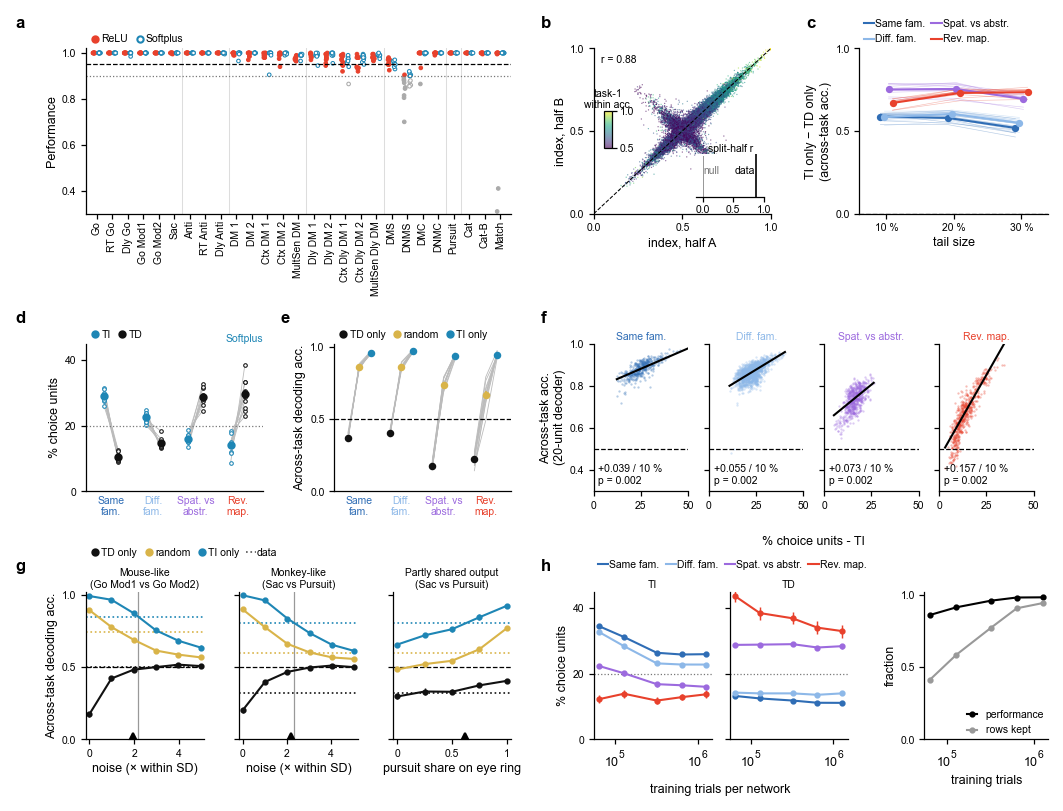

saved analysis/figures/figure_s7/figs7.{pdf,svg,png} and 8 single panels


In [10]:
DRAW = dict(a=draw_a, b=draw_b, c=draw_c, d=draw_d, e=draw_e, f=draw_f, g=draw_g, h=draw_h)

def build_full():
    fig = plt.figure(figsize=(FIG_W * MM, FIG_H * MM)); AX = {}
    for p, rects in LAYOUT.items():
        AX[p] = [add_axes_mm(fig, *r, FIG_W, FIG_H) for r in rects]; DRAW[p](AX[p])
        l, t = rects[0][0], rects[0][1]
        fig.text((l - 5 - 4) / FIG_W if p not in ('a', 'd', 'g') else 2 / FIG_W, 1 - (t - 3) / FIG_H, p, fontsize=8, weight='bold', va='bottom', ha='left')
    return fig, AX

def build_panel(p, ml=13, mb=13, mt=7, mr=3):
    rects = LAYOUT[p]; x0 = min(r[0] for r in rects); y0 = min(r[1] for r in rects)
    w = max(r[0] + r[2] for r in rects) - x0; h = max(r[1] + r[3] for r in rects) - y0; fw, fh = w + ml + mr, h + mt + mb
    if p == 'a': fh += 6
    fig = plt.figure(figsize=(fw * MM, fh * MM))
    axs = [add_axes_mm(fig, r[0] - x0 + ml, r[1] - y0 + mt, r[2], r[3], fw, fh) for r in rects]; DRAW[p](axs)
    return fig

fig, AX = build_full()
fig.savefig(OUT + NAME + '.pdf', facecolor='white'); fig.savefig(OUT + NAME + '.svg', facecolor='white')
fig.savefig(OUT + NAME + '.png', dpi=300, facecolor='white')
plt.show()
for p in LAYOUT:
    f1 = build_panel(p); f1.savefig(PANEL_DIR + f'{p}.pdf', facecolor='white'); plt.close(f1)
print('saved', OUT + NAME + '.{pdf,svg,png}', 'and', len(LAYOUT), 'single panels')

In [11]:
# ── checks: text inside the figure, column / row alignment, category counts ──
fig.canvas.draw(); R = fig.canvas.get_renderer(); fb = fig.bbox; bad = []
for t in fig.findobj(mpl.text.Text):
    if not t.get_visible() or not t.get_text().strip(): continue
    e = t.get_window_extent(R)
    if e.x0 < fb.x0 - .5 or e.y0 < fb.y0 - .5 or e.x1 > fb.x1 + .5 or e.y1 > fb.y1 + .5: bad.append((t.get_text()[:30], [round(v) for v in e.extents]))
print('clipping check:', 'all text inside the figure' if not bad else f'{len(bad)} text artists outside: {bad}')

px = fig.get_figwidth() * 25.4; py = fig.get_figheight() * 25.4
pos = {p: [ax.get_position() for ax in axs] for p, axs in AX.items()}
cols = {1: ['a', 'd', 'g'], 2: ['e'], 3: ['b', 'f', 'h'], 4: ['c']}
first = lambda p: pos[p[:-1]][1] if p.endswith('2') and p[:-1] in pos else pos[p][0]
for c, ps in cols.items():
    lefts = [first(p).x0 * px for p in ps]; print(f'column {c} {ps}: left edges {np.round(lefts, 2)} mm, spread {np.ptp(lefts):.3f} mm', '✓' if np.ptp(lefts) < .05 else '✗')
rows = {1: ['a', 'b', 'c'], 2: ['d', 'e', 'f'], 3: ['g', 'h']}
for r, ps in rows.items():
    tops = [ax.y1 * py for p in ps for ax in pos[p]]; bots = [ax.y0 * py for p in ps for ax in pos[p]]
    ok = np.ptp(tops) < .05 and np.ptp(bots) < .05 if r != 1 else np.ptp(tops) < .05
    print(f'row {r} {ps}: top spread {np.ptp(tops):.3f} mm, bottom spread {np.ptp(bots):.3f} mm', '✓' if ok else '✗')
n_pairs = pd.Series([Q.relation(a, b, 'shared') for a, b in EC.pairs_of(TASK_ORDER)]).value_counts().reindex(TYPES)
print('category counts', n_pairs.to_dict(), 'sum', n_pairs.sum())
STATS.setdefault('checks', []).extend([f'category counts {n_pairs.to_dict()} (sum {n_pairs.sum()})',
                                       'clipping: ' + ('all text inside the figure' if not bad else f'{len(bad)} artists outside')])

clipping check: all text inside the figure
column 1 ['a', 'd', 'g']: left edges [14. 14. 14.] mm, spread 0.000 mm ✓
column 2 ['e']: left edges [56.] mm, spread 0.000 mm ✓
column 3 ['b', 'f', 'h']: left edges [100. 100. 100.] mm, spread 0.000 mm ✓
column 4 ['c']: left edges [145.] mm, spread 0.000 mm ✓
row 1 ['a', 'b', 'c']: top spread 0.000 mm, bottom spread 0.000 mm ✓
row 2 ['d', 'e', 'f']: top spread 0.000 mm, bottom spread 0.000 mm ✓
row 3 ['g', 'h']: top spread 0.000 mm, bottom spread 0.000 mm ✓
category counts {'same operation': 45, 'different operation': 171, 'spatial vs abstract': 72, 'reversed mapping': 63} sum 351


In [12]:
# ── stats file ──
TITLES = dict(a='a · task performance and exclusion', b='b · split-half reliability', c='c · threshold sweep', d='d · Softplus % TI / % TD', e='e · Softplus subset decoding',
              f='f · % TI vs 20-unit decoding within category', g='g · noise-matched analog pairs and the pursuit-output dial', h='h · training trajectory', checks='checks')
lines = ['# Figure S7 — robustness of the multitask-RNN results: statistics', '',
         'Generated by `analysis/figure_s7.ipynb` from `results/panels/`. Unit of analysis = network (n = 10 unless stated);',
         'paired two-sided Wilcoxon signed-rank tests, exact p (smallest possible with n = 10: 0.002); correlations = MixedLM with a random intercept per network.', '']
# results that differ from what was expected (written from the 2026-10-20 run; re-check if the cache is recomputed)
# results that differ from what was expected (written from the v2 run of 2026-10-20; re-check if the cache is recomputed)
STATS['integrity'] = [
    'a: with the 0.90 exclusion, 12 ReLU and 6 Softplus network-task combinations are dropped, almost all DNMS; DNMS pairs keep only 1 ReLU network (net 7). '
    'Applied per network (as in Yang et al. 2019) the rule would leave 1 ReLU network. Every result below is unchanged in sign and significance from the 0.80 version.',
    'b: the anti-diagonal arm is 1.2 % of unit-pairs; their task-1 preference flips between halves in 55 % of cases (5 % elsewhere) and they are weakly selective. '
    'Only 0.56 % of unit-pairs are TI in one half and TD in the other. Requiring a consistent preference sign in both tasks keeps 88 % of unit-pairs (81 % of TD), '
    'removes the arm (r 0.88 → 0.98) and leaves the category pattern intact (TD > TI where the response changes, p = 0.002).',
    'f: refitted inside each network; all 40 network x category slopes are positive (p = 0.002 per category, the floor with 10 networks). The old MixedLM p-values are withdrawn.',
    'g: no noise level reproduces the monkey three-point. Where TI-only matches the FEF value (0.80, σ ≈ 2.35) the model gives TD-only 0.48 (data 0.32) and random 0.64 (data 0.60): '
    'noise moves the model along one curve and the FEF values lie off it. The mouse values (−2 to −1 s window) lie near the curve (where TI-only matches, σ ≈ 2.2: TD 0.49 vs 0.50, random 0.67 vs 0.74); '
    'without noise the mouse-like TD-only readout is 0.17, so near-chance TD-only in the mouse is consistent with reversing TD units diluted by noise. '
    f'Right plot: a partly shared pursuit output does reach FEF: best g = {V["best_g"]:.2f} (fully shared g = 1 is the Figure 5 set-up and overshoots the transfer).',
    'h: the thresholds are fixed from the final networks, so the categories average 20 % only at the end. Between categories the spread narrows over training '
    '(% TD 30 → 22 points, % TI 22 → 12) while the ordering is present from the first checkpoint.',
    'd, e: Softplus networks reproduce the ReLU pattern in every category.']
TITLES['integrity'] = 'results that differ from expectation'
for p in ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'checks', 'integrity']:
    if p in STATS: lines += [f'## {TITLES[p]}', ''] + [f'- {s}' for s in STATS[p]] + ['']
open(OUT + NAME + '_stats.md', 'w').write('\n'.join(lines)); print('wrote', OUT + NAME + '_stats.md')

wrote analysis/figures/figure_s7/figs7_stats.md


In [13]:
# Supplementary Table 1: write tables/ed_fig7.csv
ST.save()

ED Fig. 7: 151 rows -> analysis/tables/ed_fig7.csv
  rows per panel: a 54, b 2, c 12, d 12, e 12, f 4, g 54, h 1


,Panel,Dataset,Measure,Group / comparison,n,Unit of n,Mean,s.e.m.,Test,Statistic,P,Notebook location
0,a,ReLU networks,Task performance,Go,10,networks,1.000000,0.000000,None,None,NaN,"figure_s7.ipynb, cell 4 (a · final performance..."
1,a,ReLU networks,Task performance,RT Go,10,networks,1.000000,0.000000,None,None,NaN,"figure_s7.ipynb, cell 4 (a · final performance..."
2,a,ReLU networks,Task performance,Dly Go,10,networks,1.000000,0.000000,None,None,NaN,"figure_s7.ipynb, cell 4 (a · final performance..."
3,a,ReLU networks,Task performance,Go Mod1,10,networks,1.000000,0.000000,None,None,NaN,"figure_s7.ipynb, cell 4 (a · final performance..."
4,a,ReLU networks,Task performance,Go Mod2,10,networks,1.000000,0.000000,None,None,NaN,"figure_s7.ipynb, cell 4 (a · final performance..."
...,...,...,...,...,...,...,...,...,...,...,...,...
146,g,"Monkey-like pair, partly shared output (Sac vs...",Across-task accuracy,"g = 1.00, TD-only",10,networks,0.403770,0.013862,None,None,NaN,"figure_s7.ipynb, cell 14 (g · noise-matched an..."
147,g,"Monkey-like pair, partly shared output (Sac vs...",Across-task accuracy,"g = 1.00, random",10,networks,0.766870,0.005007,None,None,NaN,"figure_s7.ipynb, cell 14 (g · noise-matched an..."
148,g,"Monkey-like pair, partly shared output (Sac vs...",Across-task accuracy,"g = 1.00, TI-only",10,networks,0.922063,0.004912,None,None,NaN,"figure_s7.ipynb, cell 14 (g · noise-matched an..."
149,g,"Monkey-like pair, partly shared output (Sac vs...",Pursuit share on the eye ring (g),best match to the data,10,networks,0.622500,NaN,None,None,NaN,"figure_s7.ipynb, cell 14 (g · noise-matched an..."


## Full page

All panels on one 612 × 792 pt page, laid out like the .ai figure page (`layouts/figure_s7.json`); schematics are dashed placeholders. Output: `figures/figure_s7/figure_s7_full.svg`.

In [14]:
from figure_layout import assemble
assemble('figure_s7')

figure_s7: 1 panel SVGs placed -> analysis/figures/figure_s7/figure_s7_full.svg
   a  figs7.svg                                        scale 1.000 fixed canvas


'analysis/figures/figure_s7/figure_s7_full.svg'